# 01 – PID path tracking (classical control)

**Goal:** give the controller *any* path (list of waypoints) and make a differential-drive robot follow it. Validated here in simulation first, then the **same** `controllers/pid.py` is used on the real robot.

**Interface (identical for the 3 controllers):** measured pose `[x, y, θ]` + path → velocity command `(v, w)` (a `Twist`).

**How the controller works**
1. *Carrot point*: a point `lookahead` metres ahead on the path.
2. *Steering PID*: `w = PID(heading_error)`, where `heading_error` = direction to the carrot − robot heading.
3. *Speed*: `v = v_ref`, reduced when badly aligned (turn first) and ramped down near the end (so it stops on the goal).

All parameters come from the shared `config.yaml`.

In [1]:
import sys, copy, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))     # project root
import numpy as np, matplotlib.pyplot as plt, pandas as pd
from common.config import load_config
from common.paths import make_path, Path, goal_path
from common.runner import run
from common.metrics import compute_metrics
from common.plotting import plot_run, plot_signals
from controllers.pid import PIDPathTracker

cfg = load_config()
print('PID parameters from config.yaml:', cfg['controllers']['pid'])

PID parameters from config.yaml: {'v_ref': 0.18, 'lookahead': 0.3, 'heading': {'kp': 2.5, 'ki': 0.0, 'kd': 0.15}, 'cross_track': {'kp': 0.0, 'ki': 0.0, 'kd': 0.0}, 'min_speed_factor': 0.15, 'slowdown_dist': 0.35, 'deriv_filter': 0.3}


## 1. One run: circle

{'reached': True, 'time_s': 26.9, 'rmse_cte_m': 0.06031572019775807, 'max_cte_m': 0.21396404721145312, 'end_error_m': 0.05111595052082277, 'mean_speed': 0.13879284795345131, 'steering_effort': 62.42180902164156}


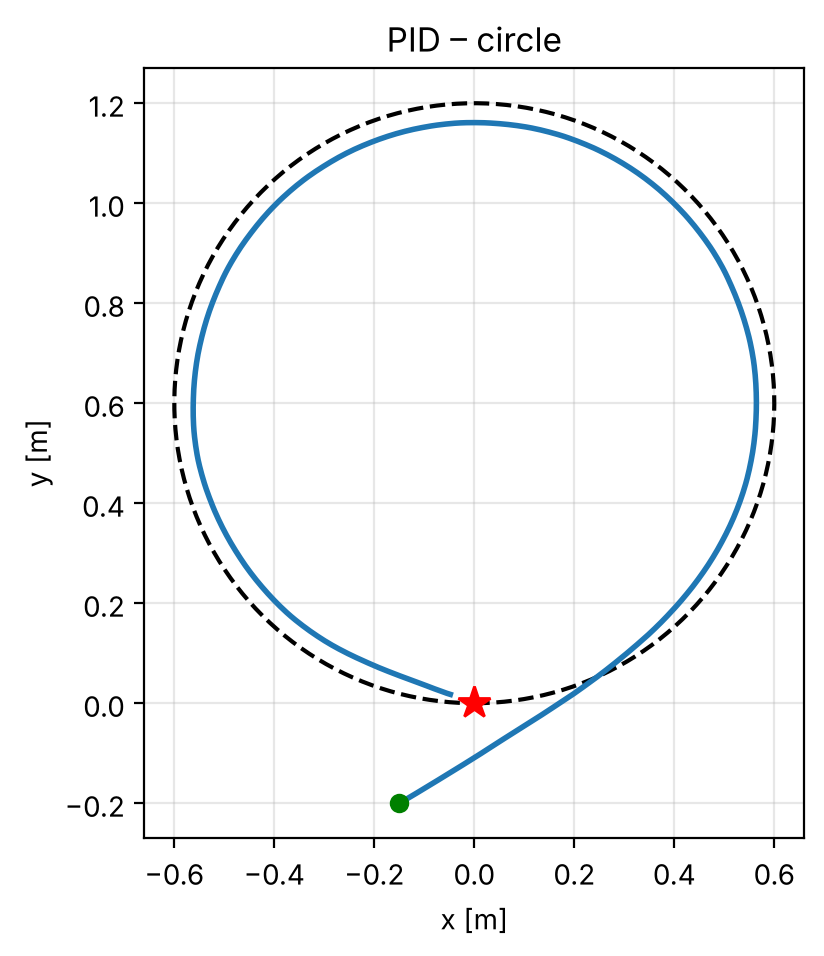

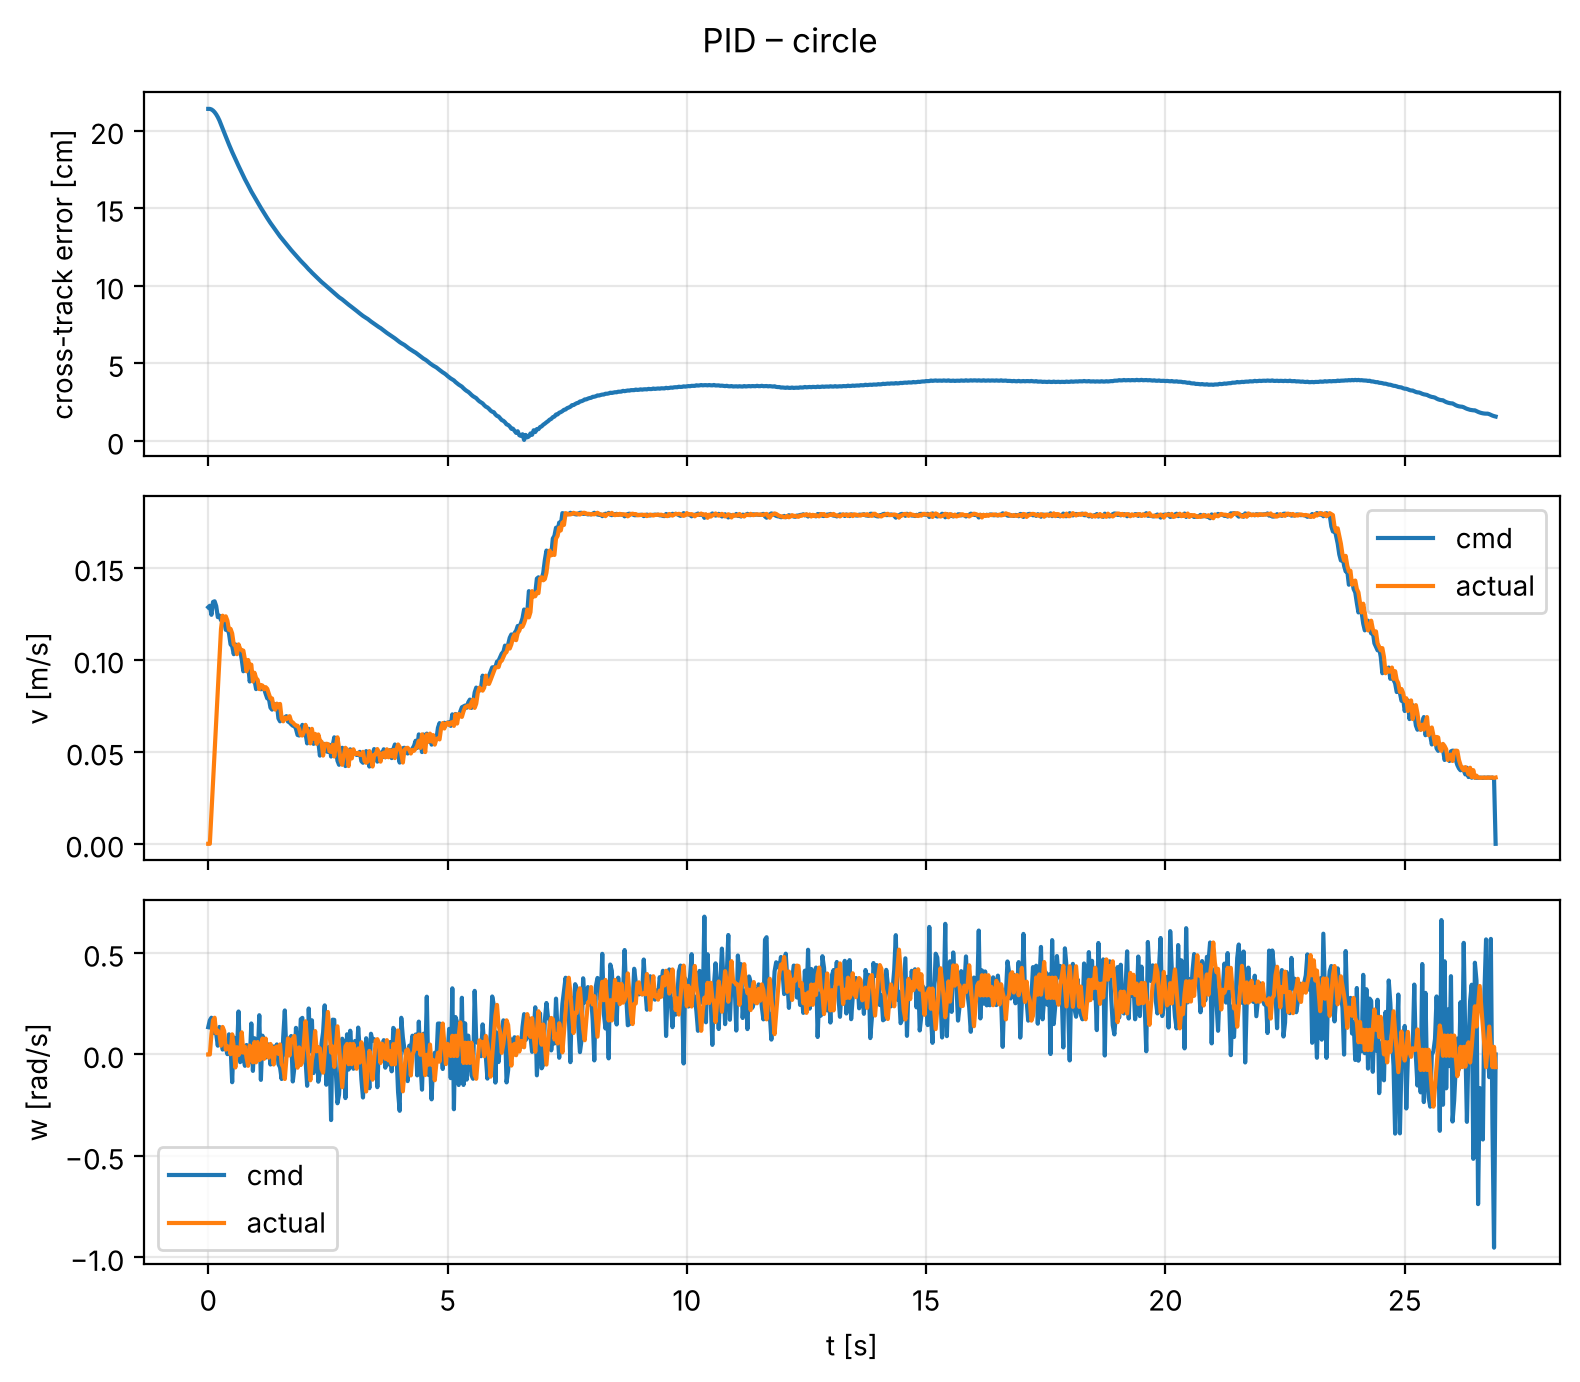

In [2]:
path = make_path(cfg['paths']['circle'])
log = run(PIDPathTracker(cfg), path, cfg)
print(compute_metrics(log, path))
plot_run(log, path, 'PID – circle'); plt.show()
plot_signals(log, 'PID – circle'); plt.show()

The robot starts *off* the path (`start_pose` in the config), so the first seconds show the controller pulling it back on. Note `w` stays within `w_max` and the actual `v`, `w` lag behind the commands (acceleration limits + latency, like the real robot).

## 2. Same controller, all preset paths

,reached,time_s,rmse_cte_m,max_cte_m,end_error_m,mean_speed,steering_effort
line,True,13.866667,0.064558,0.25,0.051423,0.153279,31.791365
circle,True,26.9,0.060316,0.213964,0.051116,0.138793,62.421809
square,True,30.566667,0.059446,0.25,0.05523,0.150127,71.233351
figure8,True,40.133333,0.035161,0.072665,0.052547,0.11406,92.024992
waypoints,True,22.633333,0.054197,0.25,0.054419,0.162057,49.844173


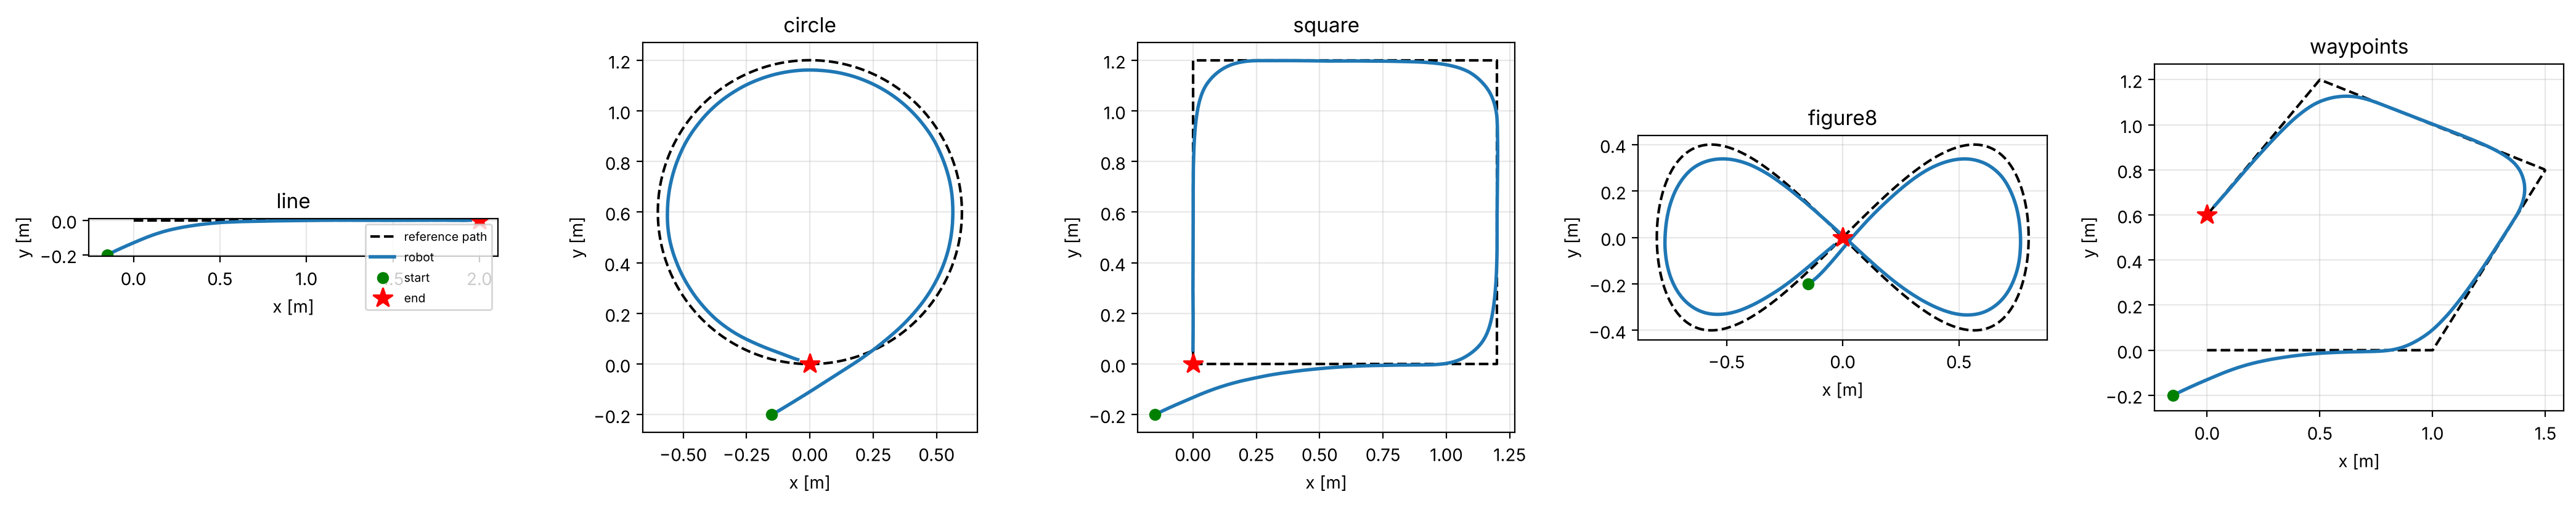

In [3]:
rows, logs = {}, {}
for name, spec in cfg['paths'].items():
    p = make_path(spec); l = run(PIDPathTracker(cfg), p, cfg)
    rows[name] = compute_metrics(l, p); logs[name] = (l, p)
display(pd.DataFrame(rows).T.round(3))
fig, axs = plt.subplots(1, len(logs), figsize=(4.2*len(logs), 4.2))
for ax, (n, (l, p)) in zip(axs, logs.items()): plot_run(l, p, n, ax)
axs[0].legend(fontsize=7); fig.tight_layout(); plt.show()

`rmse_cte_m` = root-mean-square distance to the path (includes the initial convergence from the offset start). Corners are slightly cut: that is the price of looking ahead, and it is tunable (section 4).

## 3. 'Any path' and other objectives

{'reached': True, 'time_s': 21.53333333333333, 'rmse_cte_m': 0.05044859900225735, 'max_cte_m': 0.25, 'end_error_m': 0.054506620261026956, 'mean_speed': 0.15980857228586912, 'steering_effort': 48.29395785454503}


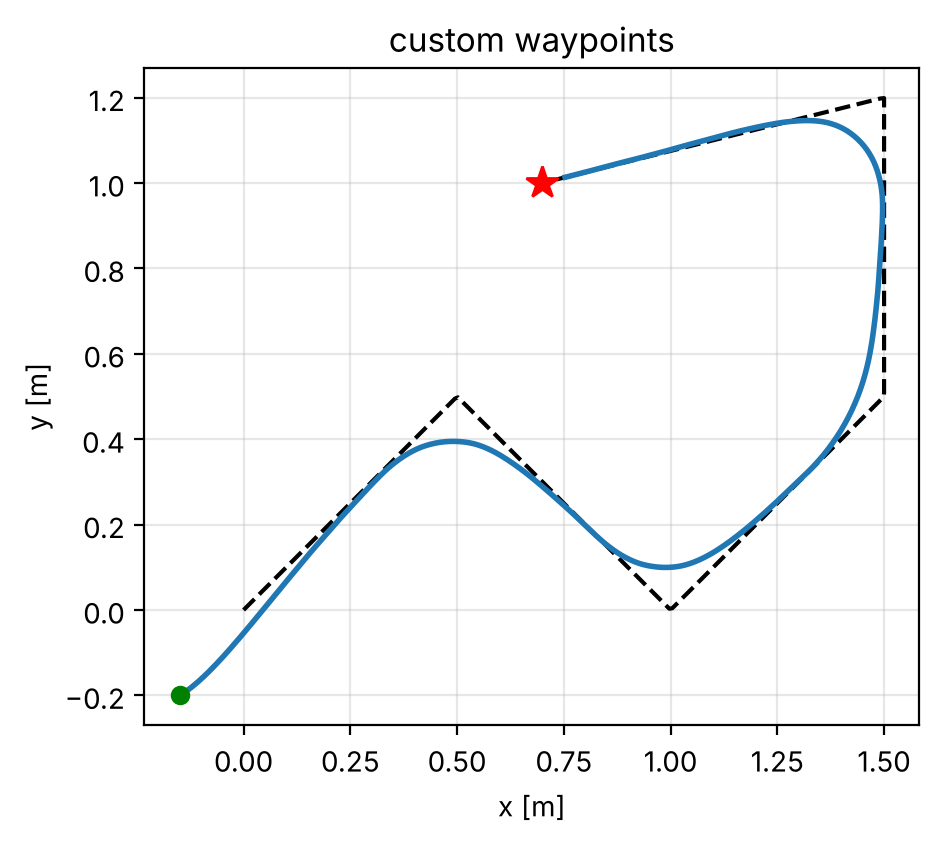

{'reached': True, 'time_s': 10.866666666666667, 'rmse_cte_m': 0.006015771396727816, 'max_cte_m': 0.014442458796621784, 'end_error_m': 0.055538616343665456, 'mean_speed': 0.14750867912493734, 'steering_effort': 26.099325651791688}


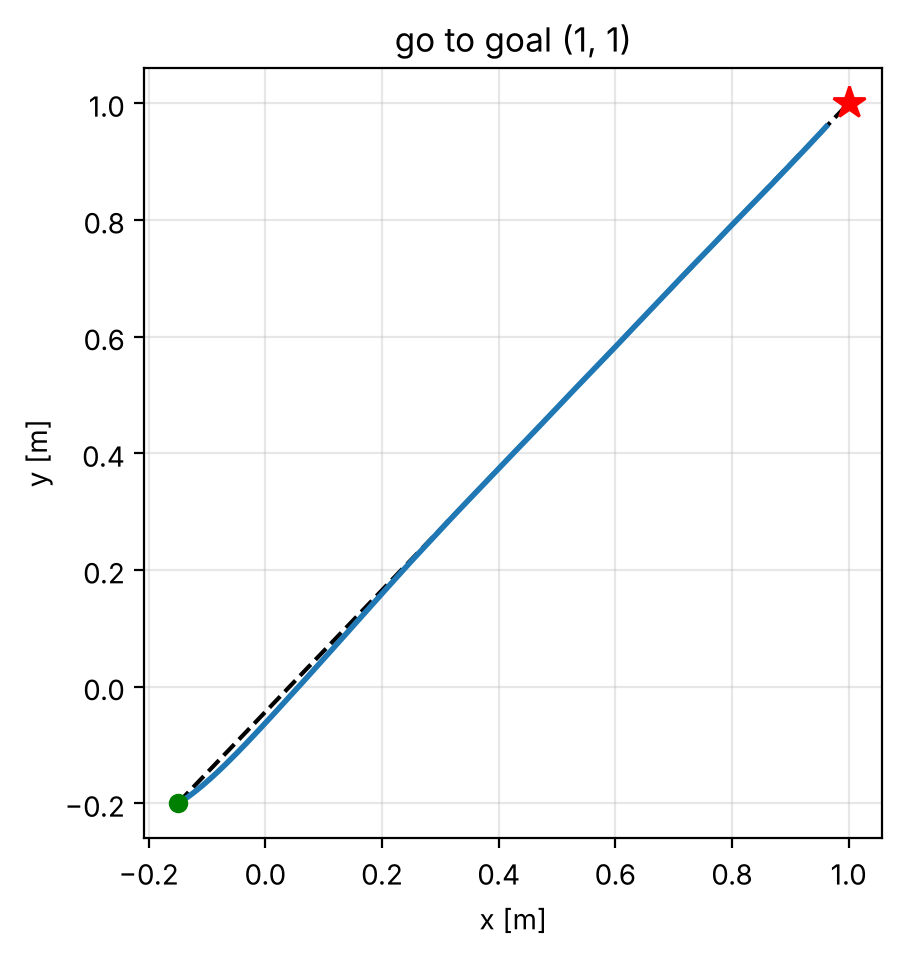

In [4]:
# (a) arbitrary user waypoints
my_path = Path([[0,0],[0.5,0.5],[1.0,0.0],[1.5,0.5],[1.5,1.2],[0.7,1.0]])
l = run(PIDPathTracker(cfg), my_path, cfg); print(compute_metrics(l, my_path))
plot_run(l, my_path, 'custom waypoints'); plt.show()

# (b) go-to-goal = path made of start -> goal
start = np.array(cfg['start_pose'][:2]); goal = np.array([1.0, 1.0])
gp = goal_path(start, goal)
l = run(PIDPathTracker(cfg), gp, cfg); print(compute_metrics(l, gp))
plot_run(l, gp, 'go to goal (1, 1)'); plt.show()

Different objectives = different *paths* fed to the same controller: path following, point-to-point navigation, and (later) the output of a planner/obstacle avoidance. This keeps the interface the same for the symbolic and RL controllers.

## 4. Tuning: what do P, I, D and the lookahead actually do?

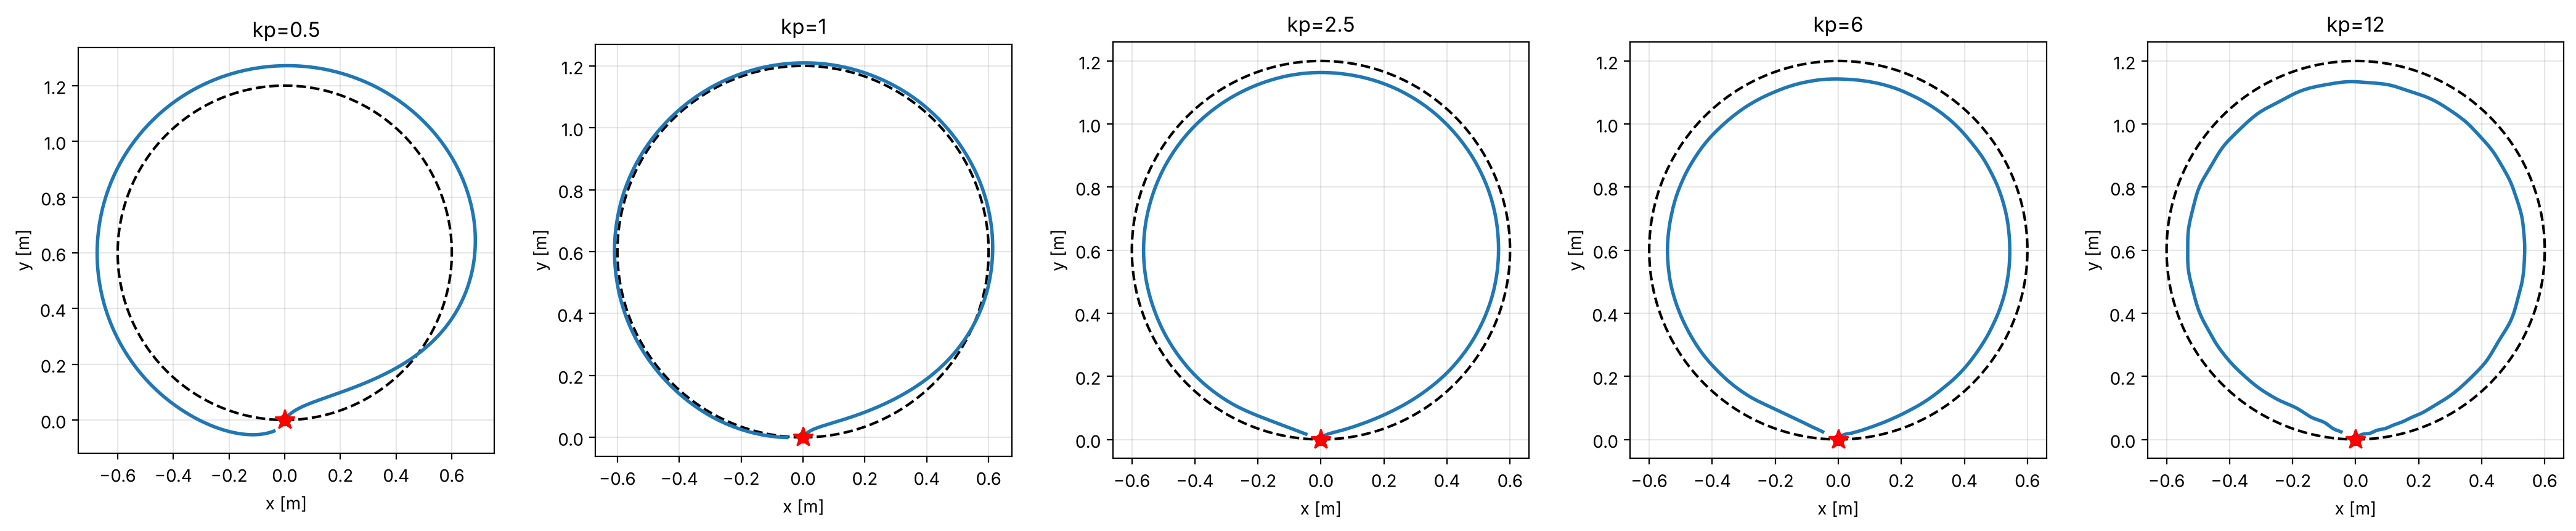

,reached,time_s,rmse_cte_m,max_cte_m,steering_effort
kp=0.5,True,31.466667,0.067491,0.091779,11.646575
kp=1,True,27.0,0.018626,0.044392,21.099874
kp=2.5,True,24.933333,0.035296,0.044211,40.34561
kp=6,True,24.133333,0.050575,0.059713,54.093803
kp=12,True,24.033333,0.056898,0.070243,65.455999


In [5]:
COLS = ['reached', 'time_s', 'rmse_cte_m', 'max_cte_m', 'steering_effort']

def run_with(modify, path_name='circle', start=(0, 0, 1.0), cfg0=cfg):
    # start ON the path but with the robot rotated ~57 deg: isolates the controller's own behaviour
    c = copy.deepcopy(cfg0); modify(c)
    p = make_path(c['paths'][path_name]); l = run(PIDPathTracker(c), p, c, start_pose=list(start))
    return l, p, compute_metrics(l, p)

def set_h(kp, ki=0, kd=0):
    def f(c): c['controllers']['pid']['heading'] = dict(kp=kp, ki=ki, kd=kd)
    return f

# --- P gain ---
variants = {'kp=0.5': set_h(0.5), 'kp=1': set_h(1), 'kp=2.5': set_h(2.5), 'kp=6': set_h(6), 'kp=12': set_h(12)}
fig, axs = plt.subplots(1, len(variants), figsize=(4.2*len(variants), 4.2)); rows = {}
for ax, (n, f) in zip(axs, variants.items()):
    l, p, m = run_with(f); rows[n] = m; plot_run(l, p, n, ax)
fig.tight_layout(); plt.show()
display(pd.DataFrame(rows).T[COLS].round(3))

**P gain (proportional).** Too low (`kp=0.5`) and the robot reacts slowly: it lags and swings wide. Increasing `kp` makes it react faster, but `steering_effort` (total variation of the steering command) rises steadily, because the noisy heading measurement is multiplied by `kp` and sent straight to the motors. Past a point you only buy jitter. The best tracking here is around `kp=1`; the config default of 2.5 reacts faster at the cost of more jitter. Pick the value on the real robot by watching both the tracking error and how nervous the wheels sound.

In [6]:
# --- D term: does it help? ---
rows = {}
for n, f in {'P (kp=2.5)': set_h(2.5), 'PD kd=0.15': set_h(2.5, 0, 0.15), 'PD kd=0.5': set_h(2.5, 0, 0.5), 'PD kd=1.0': set_h(2.5, 0, 1.0)}.items():
    rows[n] = run_with(f)[2]
display(pd.DataFrame(rows).T[COLS].round(3))

,reached,time_s,rmse_cte_m,max_cte_m,steering_effort
P (kp=2.5),True,24.933333,0.035296,0.044211,40.34561
PD kd=0.15,True,24.933333,0.035035,0.04473,58.006851
PD kd=0.5,True,24.933333,0.035154,0.045886,65.94424
PD kd=1.0,True,24.933333,0.037668,0.049769,70.673678


**D gain (derivative).** In theory it damps oscillations. Here it does **not** help: the heading signal is noisy (`yaw_std` in the config), and differentiating noise amplifies it (steering effort grows with `kd`) while the tracking error doesn't improve. Practical lesson: keep `kd` small (or zero) unless the pose is filtered first. Re-check this on the real robot, where the noise level is different.

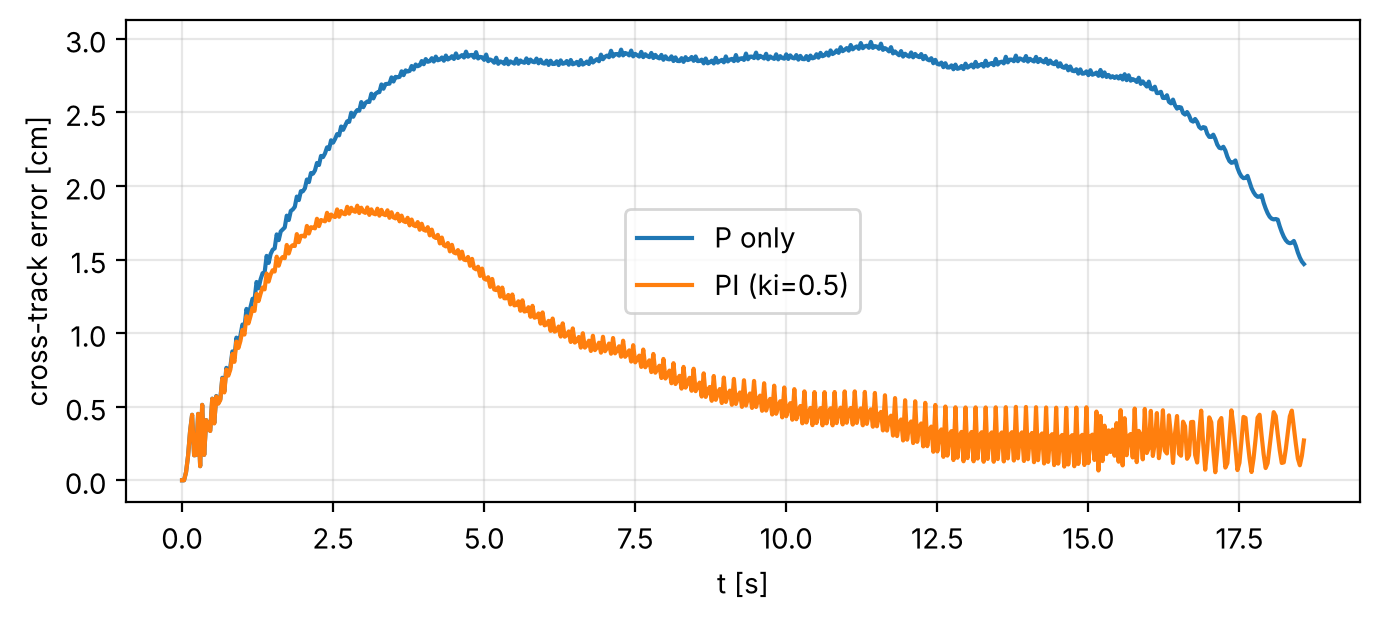

,reached,max_cte_m,steady_offset_cm
P only,True,0.029793,2.680864
PI (ki=0.5),True,0.018663,0.371737


In [7]:
# --- I term: needs a persistent disturbance to matter. Simulate unequal wheels = constant yaw drift ---
cfg_bias = copy.deepcopy(cfg); cfg_bias['robot']['w_bias'] = 0.25          # rad/s
cfg_bias['paths']['long_line'] = {'type': 'line', 'length': 3.0}
rows = {}; fig, ax0 = plt.subplots(figsize=(7, 3.2))
for n, f in {'P only': set_h(2.5), 'PI (ki=0.5)': set_h(2.5, 0.5)}.items():
    l, p, m = run_with(f, 'long_line', (0, 0, 0), cfg_bias)
    k = l['t'] > 8; m['steady_offset_cm'] = 100*np.abs(l['cte'][k]).mean(); rows[n] = m
    ax0.plot(l['t'], 100*l['cte'], label=n)
ax0.set_xlabel('t [s]'); ax0.set_ylabel('cross-track error [cm]'); ax0.legend(); ax0.grid(alpha=.3)
fig.tight_layout(); plt.show()
display(pd.DataFrame(rows).T[['reached', 'max_cte_m', 'steady_offset_cm']].round(3))

**I gain (integral).** With a constant disturbance (here a yaw drift, like unequal wheel diameters), P alone settles with a permanent offset from the path. Adding `ki` removes it (the integrator absorbs the bias). In an ideal simulation `ki` is useless, which is why the default is 0; turn it on if the real robot drifts to one side.

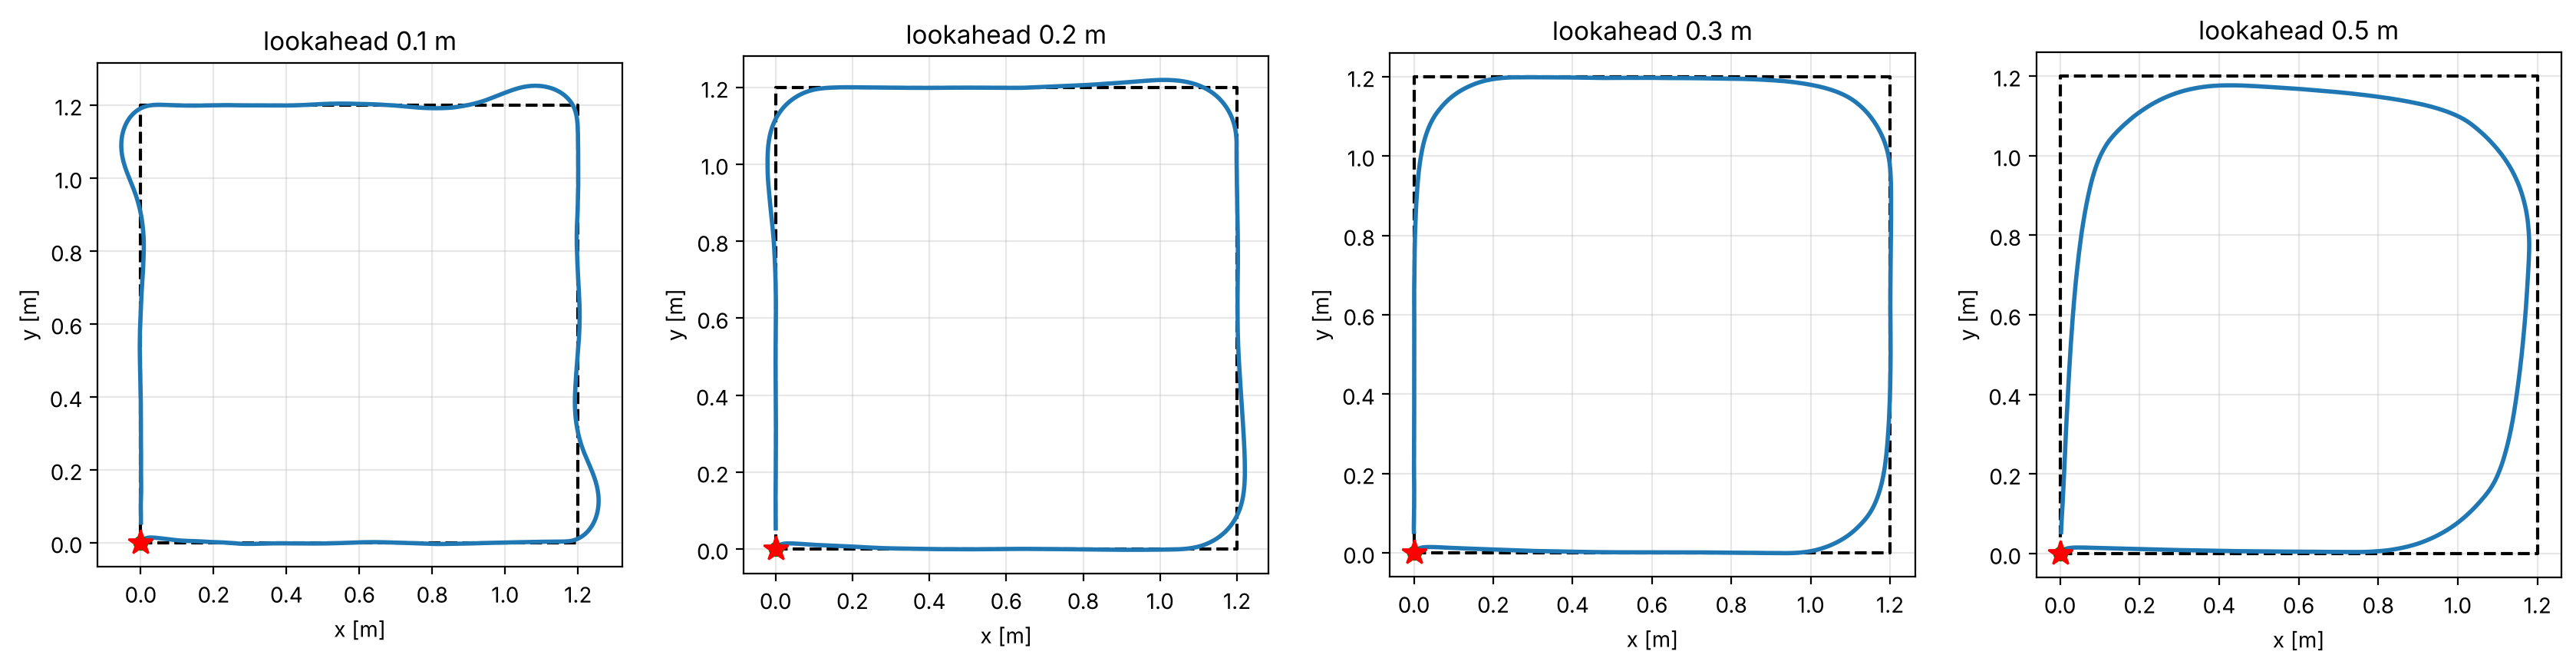

,reached,time_s,rmse_cte_m,max_cte_m,steering_effort
lookahead=0.1,True,34.3,0.016792,0.056623,78.607013
lookahead=0.2,True,31.666667,0.010251,0.037591,69.941721
lookahead=0.3,True,30.3,0.017817,0.074249,70.061765
lookahead=0.5,True,28.333333,0.050363,0.141464,60.796571


In [8]:
# --- Lookahead distance ---
rows = {}
fig, axs = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, L in zip(axs, [0.10, 0.20, 0.30, 0.50]):
    def f(c, L=L): c['controllers']['pid']['lookahead'] = L
    l, p, m = run_with(f, 'square'); rows[f'lookahead={L}'] = m; plot_run(l, p, f'lookahead {L} m', ax)
fig.tight_layout(); plt.show()
display(pd.DataFrame(rows).T[COLS].round(3))

**Lookahead.** Small = twitchy steering (higher `steering_effort`) and no real gain in accuracy below ~0.2 m; large = smooth but it cuts corners (`rmse_cte_m` jumps at 0.5 m). This is the main trade-off of the classical approach, and a good baseline to compare the other two controllers against.

## 5. Robustness: measurement noise and command latency (sim-to-real gap)

In [9]:
rows = {}
for label, (ns, delay, kp) in {'ideal (no noise, no delay)': (0, 0, 2.5), 'nominal (config)': (1, None, 2.5), '3x noise': (3, None, 2.5),
                              'delay 200 ms': (1, 6, 2.5), 'delay 400 ms': (1, 12, 2.5), 'delay 670 ms': (1, 20, 2.5),
                              'delay 670 ms, kp=6': (1, 20, 6)}.items():
    def f(c, ns=ns, d=delay, kp=kp):
        c['noise']['pos_std'] *= ns; c['noise']['yaw_std'] *= ns; set_h(kp)(c)
        if d is not None: c['robot']['cmd_delay_steps'] = d
    rows[label] = run_with(f)[2]
display(pd.DataFrame(rows).T[COLS].round(3))

,reached,time_s,rmse_cte_m,max_cte_m,steering_effort
"ideal (no noise, no delay)",True,24.933333,0.035217,0.044336,10.919577
nominal (config),True,24.933333,0.035296,0.044211,40.34561
3x noise,True,24.166667,0.038316,0.04756,56.51177
delay 200 ms,True,25.0,0.034985,0.043256,39.509058
delay 400 ms,True,25.1,0.034596,0.041509,38.834855
delay 670 ms,True,33.133333,0.039181,0.076662,37.817617
"delay 670 ms, kp=6",True,39.433333,0.056121,0.116444,37.147309


With these moderate gains the tracker tolerates up to ~400 ms of latency with almost no loss; beyond that it gets slower (the run takes longer) and tracking degrades, and a higher `kp` makes it worse, not better. Measurement noise mainly shows up as extra steering effort. On the real setup, commands cross the LAN (laptop -> Pi) and the serial link, so measure the real latency and update `cmd_delay_steps`. Note the Pi stops the robot if no command arrives for 0.5 s.

## 6. What to do next
1. **Measure on the real robot** and update `config.yaml` (values marked *assumed*): accelerations, command latency, pose noise, wheel bias.
2. Wrap `PIDPathTracker` in a ROS 2 node: subscribe `/robot_pose`, publish `/cmd_vel` (the mux accepts it at priority 50; the joystick at 100 can always override = emergency stop).
3. Next controllers (`controllers/symbolic.py`, `controllers/rl.py`) plug into the same interface and are evaluated with the same paths and metrics.